In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from glob import glob

from astropy.io import fits
from astropy.wcs import WCS

from reproject import reproject_interp
from reproject.mosaicking import find_optimal_celestial_wcs

from AstroColour.AstroColour import RGB

# epoch_colour_utils.py must be in the same folder as this notebook
sys.path.append('.')
from epoch_colour_utils import assign_epochs, build_epoch_images, make_colour_cube

%matplotlib widget

In [2]:
plt.rc('text', usetex=True)
plt.rc('font', family='serif')

inches_per_pt   = 1.0 / 72.27
text_width_pt   = 508.0          # \the\textwidth in your LaTeX document
fig_width_full  = text_width_pt * inches_per_pt * 1.5

In [3]:
image_folder = '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/'

image_files = glob(image_folder + '*.fits')

image_files

['/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f070w_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f356w_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f250m_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f115w_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f444w_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f187n_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f300m_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f335m_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_nircam_clear-f090w_i2d.fits',
 '/Users/zalane/Desktop/JWST-NIRCam-2024aecx/MAST/JWST/jw09258-o014_t002_

F070W


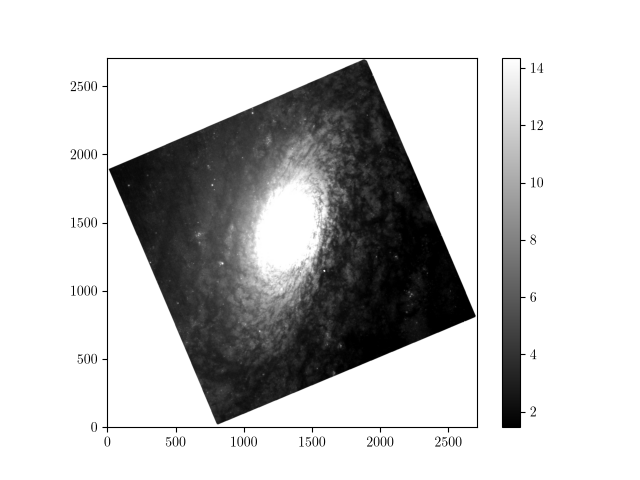

F356W


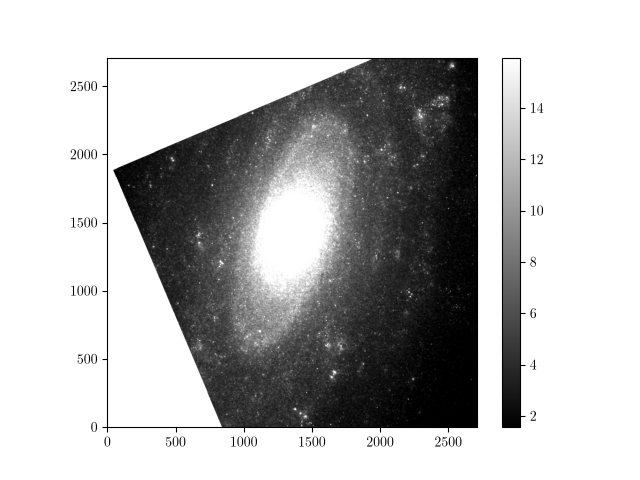

F250M


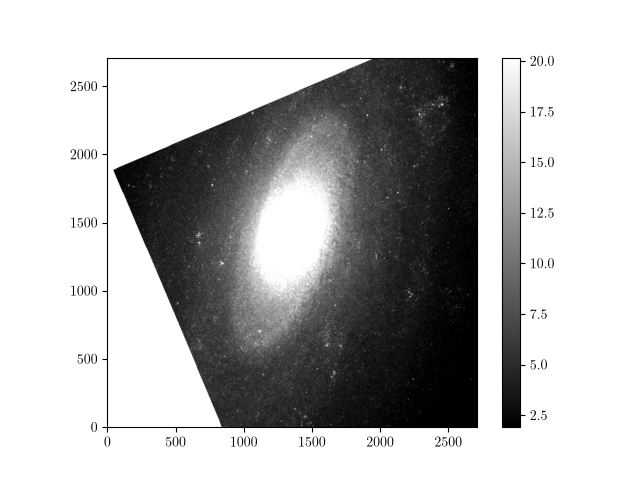

F115W


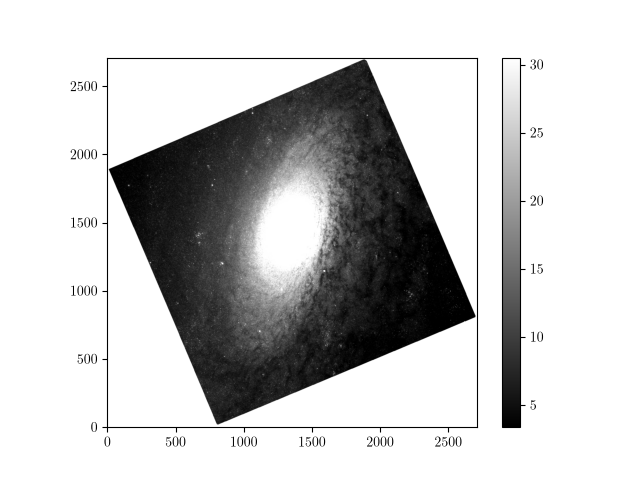

F444W


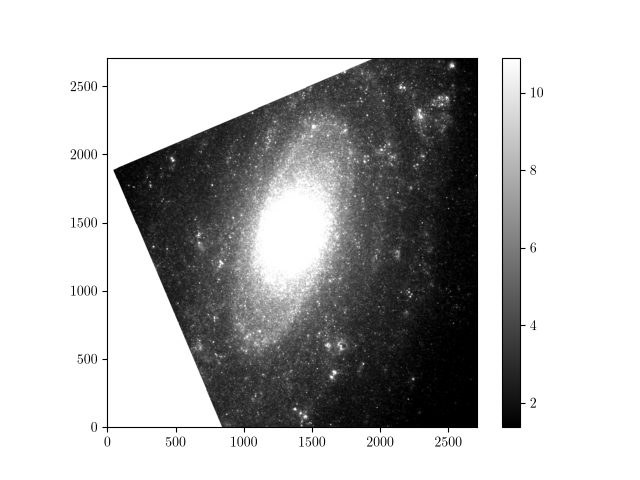

F187N


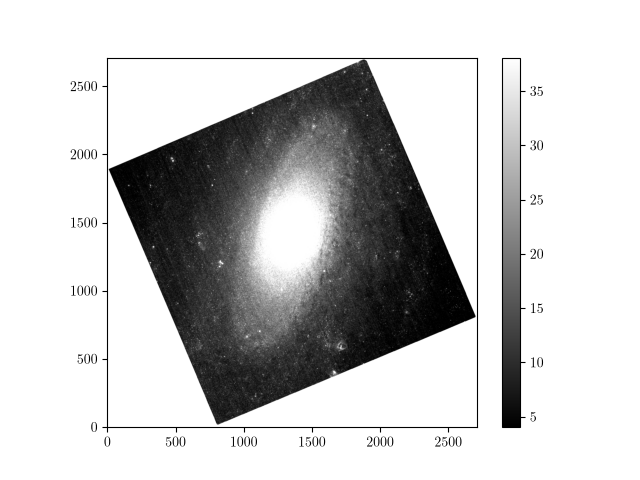

F300M


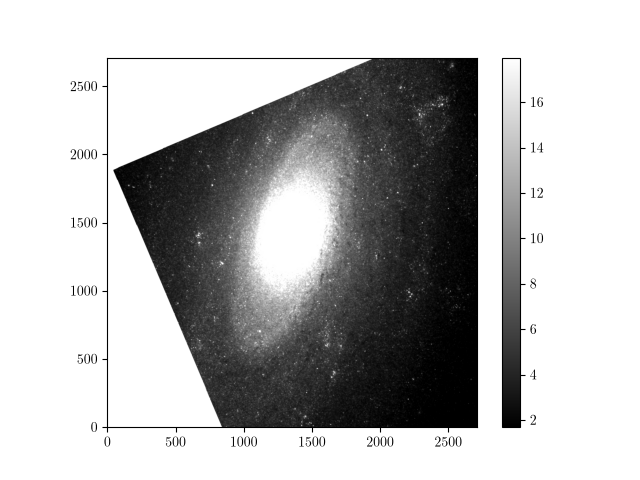

F335M


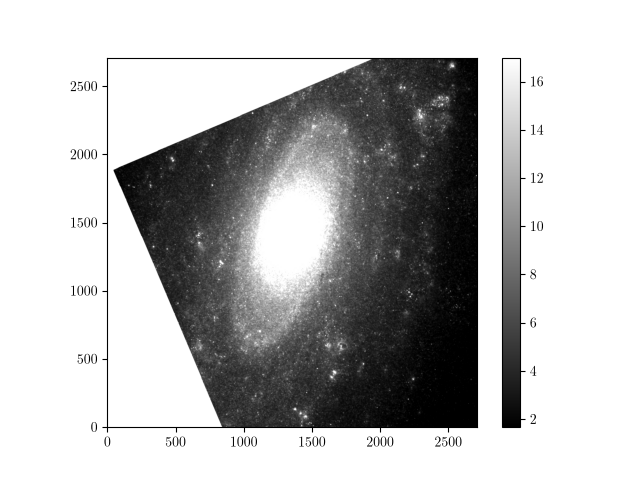

F090W


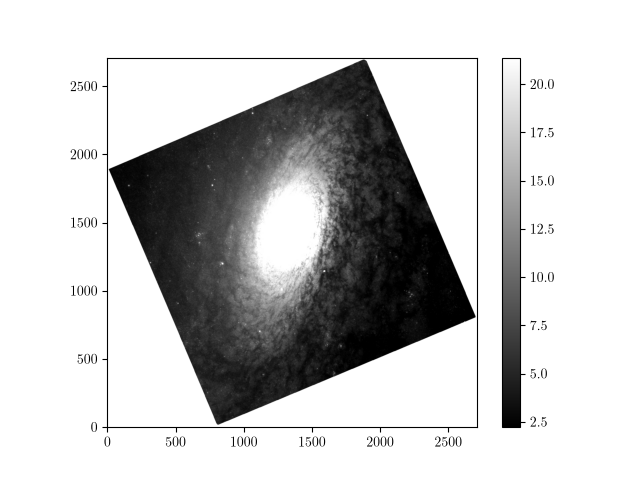

F150W


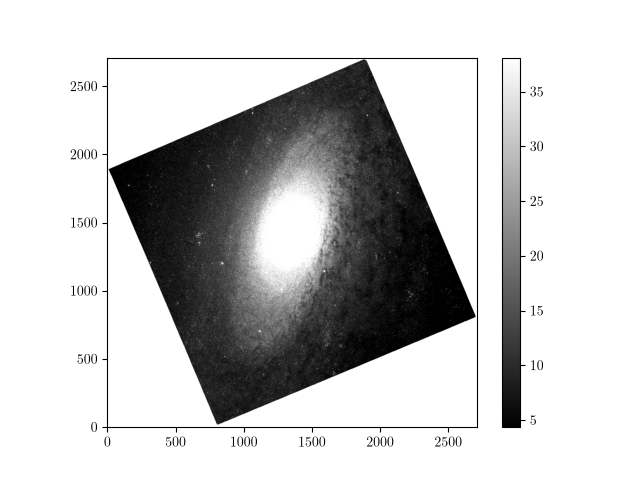

Pixel coordinates of the target: x=889.0189862129623, y=1544.3762900209356


In [4]:
ra, dec = 166.45643462, -0.0348496976029

filter_list = []
colour_cube = []

for i, image in enumerate(image_files):
    hdulist = fits.open(image)
    header = hdulist[0].header
    wcs = WCS(hdulist[1].header)
    data = hdulist[1].data
    
    if i == 0:
        master_wcs, shape_out = find_optimal_celestial_wcs((data, wcs), frame='icrs', auto_rotate=False)
        reprojected_data, footprint = reproject_interp((data, wcs), master_wcs, shape_out=shape_out)
    if i != 0:
    #     master_wcs, shape_out = find_optimal_celestial_wcs(hdulist, frame='icrs', auto_rotate=False)
        reprojected_data, footprint = reproject_interp((data, wcs), master_wcs, shape_out=shape_out)
    
    print(header['FILTER'])
    filter_list.append(header['FILTER'])
    
    plt.figure()
    plt.imshow(reprojected_data, cmap='gray', origin='lower', vmin = np.nanpercentile(reprojected_data, 5), vmax = np.nanpercentile(reprojected_data, 95))
    plt.colorbar()
    plt.show()
    
    colour_cube.append(reprojected_data)
    
x1, y1 = master_wcs.all_world2pix(ra, dec, 0)
print(f"Pixel coordinates of the target: x={x1}, y={y1}")

In [5]:
channel_filters = {'color1': 'F070W', 
                   'color2': 'F090W', 
                   'color3': 'F115W', 
                   'color4': 'F150W', 
                   'color5': 'F187N',
                   'color6': 'F250M', 
                   'color7': 'F300M', 
                   'color8': 'F335M', 
                   'color9': 'F356W', 
                   'color10': 'F444W'}

channel_filters = {'color1': 'F070W', 
                   'color2': 'F090W', 
                   'color3': 'F115W', 
                   'color4': 'F150W', 
                #    'color5': 'F187N',
                #    'color6': 'F250M', 
                #    'color7': 'F300M', 
                #    'color8': 'F335M', 
                   'color9': 'F356W', 
                   'color10': 'F444W'}

for i, key in enumerate(channel_filters):
    v = channel_filters[key]
    print(f"{i}: {key} -> {v}")
    idx = filter_list.index(v)
    print(f"Index in filter_list: {idx}")
    # print(filter_list[i])

new_colour_cube = [colour_cube[filter_list.index(channel_filters[key])] for i, key in enumerate(channel_filters)]

0: color1 -> F070W
Index in filter_list: 0
1: color2 -> F090W
Index in filter_list: 8
2: color3 -> F115W
Index in filter_list: 3
3: color4 -> F150W
Index in filter_list: 9
4: color9 -> F356W
Index in filter_list: 1
5: color10 -> F444W
Index in filter_list: 4


In [6]:
filter_list

['F070W',
 'F356W',
 'F250M',
 'F115W',
 'F444W',
 'F187N',
 'F300M',
 'F335M',
 'F090W',
 'F150W']

In [7]:
new_colour_cube

[array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]], shape=(2711, 2710)),
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]], shape=(2711, 2710)),
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]], shape=(2711, 2710)),
 array([[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, n

### Configuration
`filter_list` — filters to stack, in any order.

`channel_filters` — which filter(s) feed each RGB channel. This is my best guess at a sensible mapping (short wavelength → blue, long → red) — check/edit it for your target.

### Build the colour image
Tune `intensities` / `gamma` / `uppers` / `lowers` by eye for this epoch, re-running this cell as needed.

In [8]:
rgb = RGB(new_colour_cube,
          save=False, save_name='colour_image', save_folder='.',
          epsf_plot=False, epsf=False,
          bkg_plot=False, temp_save=True, run=False, manual_override=0)

In [9]:
channel_filters

{'color1': 'F070W',
 'color2': 'F090W',
 'color3': 'F115W',
 'color4': 'F150W',
 'color9': 'F356W',
 'color10': 'F444W'}

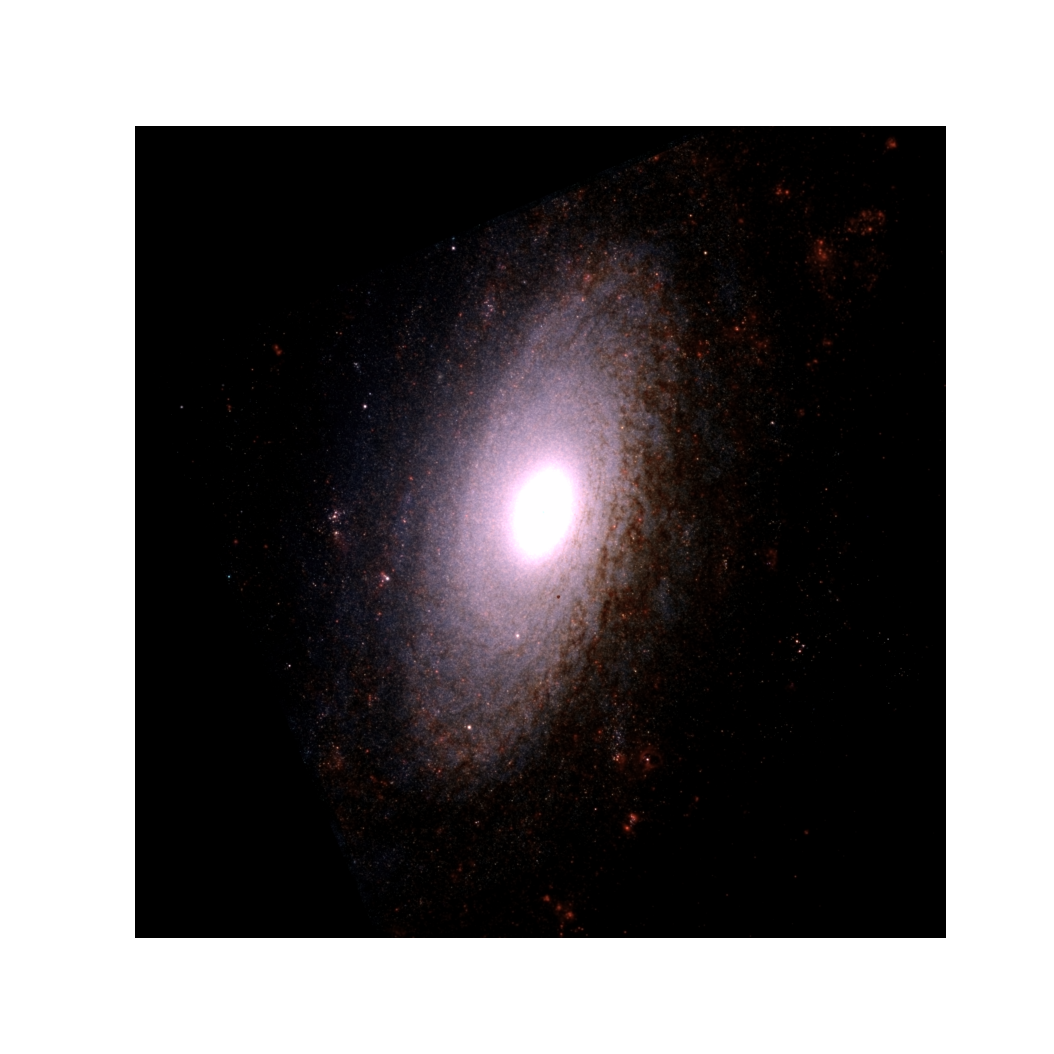

In [10]:
colour = rgb.master_plot(new_colour_cube,
                          colours=None,
                          intensities=[1, 1.1, 1, 1, 1.1, 1],
                          gamma=[1.15, 1.15, 1.15, 1.15, 1.15, 1.15],
                          norms=['asinh', 'asinh', 'asinh', 'asinh', 'asinh', 'asinh'],   # unused by asinh_sigma, harmless to leave
                          uppers=[99.9999, 99.9999, 99.9999, 99.9999, 99.9999, 99.9999],        # white-point percentile
                          lowers=[0.01, 0.01, 0.01, 0.01, 0.01, 0.01],              # black point, in noise-sigma
                          cmap_choice='rainbow',
                          interactive=False,
                          method='asinh_sigma',#'asinh_sigma',
                          chroma_denoise_final=True)

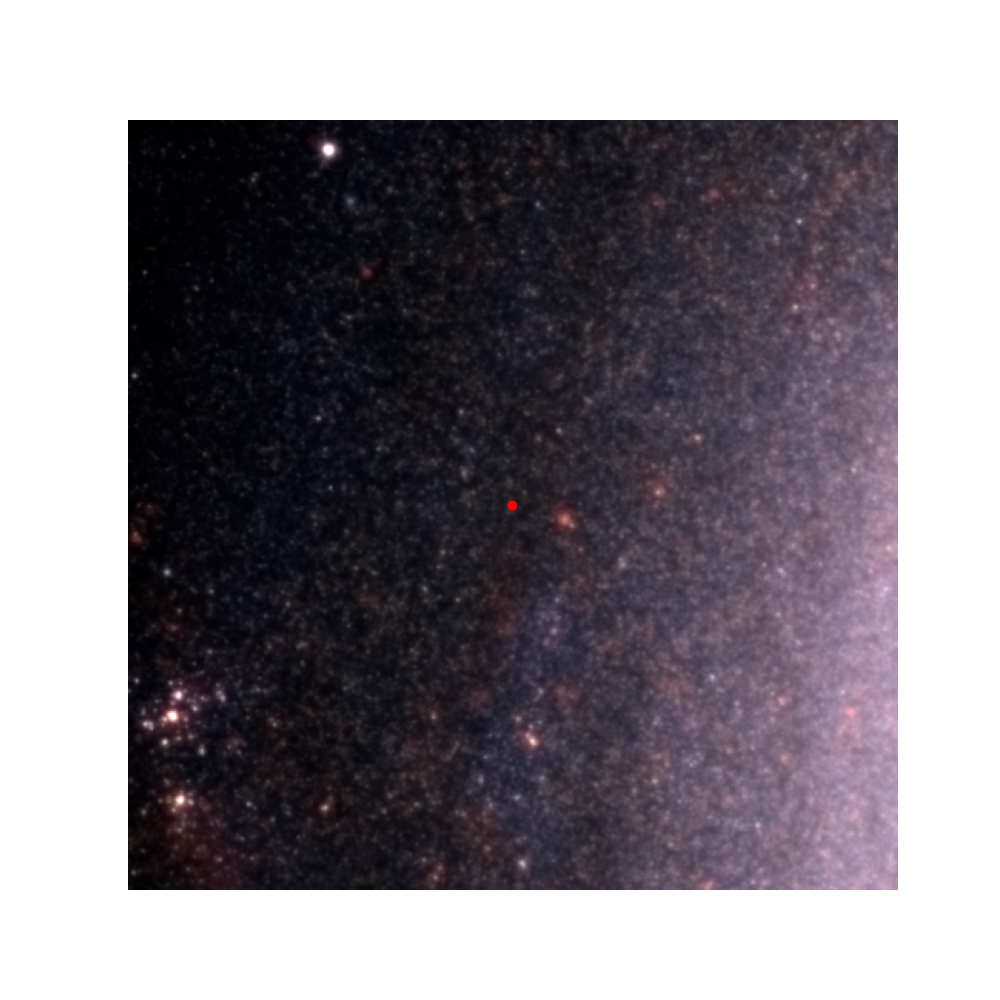

In [14]:
plt.figure(figsize=(10, 10))
plt.imshow(colour, origin='lower')
plt.scatter(x1, y1, color = 'r')
plt.axis('off')
plt.xlim(x1 - 250, x1 + 250)
plt.ylim(y1 - 250, y1 + 250)
plt.show()


In [12]:
from scipy import ndimage

allwhite = np.all(colour >= 1.0, axis=-1)
filled = ndimage.binary_fill_holes(allwhite)
colour_clean = colour.copy()
colour_clean[filled] = 1.0
colour = colour_clean

### Optional: reproject to north-up before saving

In [ ]:
colour_cube_northup = []
for i in range(3):
    wcs_out, shape_out = find_optimal_celestial_wcs((colour[:, :, i], master_wcs), frame='icrs', auto_rotate=True)
    array_north_up, footprint = reproject_interp((colour[:, :, i], master_wcs), wcs_out, shape_out=shape_out)
    colour_cube_northup.append(array_north_up)
colour_cube_northup = np.dstack(colour_cube_northup)

plt.figure(figsize=(fig_width_full, fig_width_full))
plt.imshow(colour_cube_northup, origin='lower')
plt.show()

colour = colour_cube_northup

### Save
Saves as `colour_image_DDMMYYYY.npy` for this epoch.

In [15]:
save_name = f'colour_image_05-06-2025.npy'
np.save(save_name, colour)
print(f"Saved {save_name}")

Saved colour_image_05-06-2025.npy


In [ ]:
# colour = np.load(save_name)  # reload check